### 1. Project Title: Predictive Analysis of Airline Routes and Airport Operations Using Deep Learning

In this notebook, we implement a Long Short-Term Memory (LSTM) network to predict airport operations metrics (such as hourly flight delays or passenger volume) based on historical sequence data.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

# Set random seed for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

### 2. Generate/Simulate Operations Data
We generate a synthetic time-series dataset simulating daily or hourly flight delays at a busy airport hub, incorporating weekly seasonality and noise.

,Hour,Average_Delay
0,0,32.483571
1,1,29.538805
2,2,33.039648
3,3,36.395684
4,4,26.104867


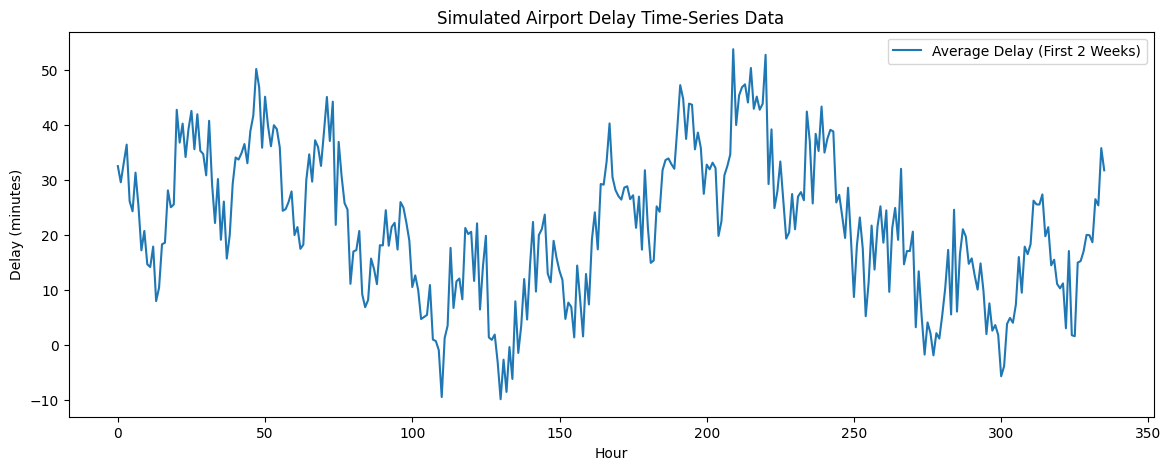

In [2]:
# Generate synthetic time series data (e.g., average delay in minutes over 1000 hours)
time_steps = 1000
time = np.arange(time_steps)

# Create a baseline with trend, weekly seasonality (period = 24 * 7), and noise
trend = 0.01 * time
seasonality = 15 * np.sin(2 * np.pi * time / 168) + 10 * np.cos(2 * np.pi * time / 24)
noise = np.random.normal(0, 5, size=time_steps)
delay_data = 20 + trend + seasonality + noise

# Create DataFrame
df = pd.DataFrame({'Hour': time, 'Average_Delay': delay_data})
display(df.head())

# Plot the data
plt.figure(figsize=(14, 5))
plt.plot(df['Hour'][:336], df['Average_Delay'][:336], label='Average Delay (First 2 Weeks)')
plt.xlabel('Hour')
plt.ylabel('Delay (minutes)')
plt.title('Simulated Airport Delay Time-Series Data')
plt.legend()
plt.show()

### 3. Data Preprocessing and Sequencing
LSTMs require sequence inputs. We scale the data between 0 and 1, and restructure it into sliding windows of past values to predict the next value.

In [3]:
# Scale the target variable
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(df[['Average_Delay']])

# Function to create sequences of historical context
def create_sequences(data, seq_length):
    X, y = [], []
    for i in range(len(data) - seq_length):
        X.append(data[i:i + seq_length])
        y.append(data[i + seq_length])
    return np.array(X), np.array(y)

SEQUENCE_LENGTH = 24  # Use past 24 hours to predict the next hour
X, y = create_sequences(scaled_data, SEQUENCE_LENGTH)

# Split into Train and Test sets (80/20 split)
split_idx = int(len(X) * 0.8)
X_train, X_test = X[:split_idx], X[split_idx:]
y_train, y_test = y[:split_idx], y[split_idx:]

print(f"Training set shape: X={X_train.shape}, y={y_train.shape}")
print(f"Test set shape: X={X_test.shape}, y={y_test.shape}")

Training set shape: X=(780, 24, 1), y=(780, 1)
Test set shape: X=(196, 24, 1), y=(196, 1)


### 4. Build and Train the LSTM Architecture
We define a sequential LSTM network with Dropout layers to prevent overfitting.

In [4]:
model = Sequential([
    LSTM(64, return_sequences=True, input_shape=(X_train.shape[1], X_train.shape[2])),
    Dropout(0.2),
    LSTM(32, return_sequences=False),
    Dropout(0.2),
    Dense(16, activation='relu'),
    Dense(1)
])

model.compile(optimizer='adam', loss='mean_squared_error')
model.summary()

# Train the model
history = model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 24, 64)         │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 24, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,857 (116.63 KB)

 Trainable params: 29,857 (116.63 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 4s 39ms/step - loss: 0.1161 - val_loss: 0.0199
Epoch 2/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0352 - val_loss: 0.0221
Epoch 3/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.0275 - val_loss: 0.0190
Epoch 4/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.0264 - val_loss: 0.0172
Epoch 5/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.0259 - val_loss: 0.0167
Epoch 6/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.0254 - val_loss: 0.0164
Epoch 7/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0221 - val_loss: 0.0162
Epoch 8/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - loss: 0.0223 - val_loss: 0.0157
Epoch 9/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - loss: 0.0219 - val_loss: 0.0162
Epoch 10/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - loss: 0.0209 - val_loss: 0.0143
Epoch 11/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - loss: 0.0180 - val_loss: 0.0134
Epoch 12/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0

### 5. Evaluate the Predictions
We plot training losses, generate predictions on the test set, inverse-transform them back to their original scale, and plot the actual vs. predicted values.

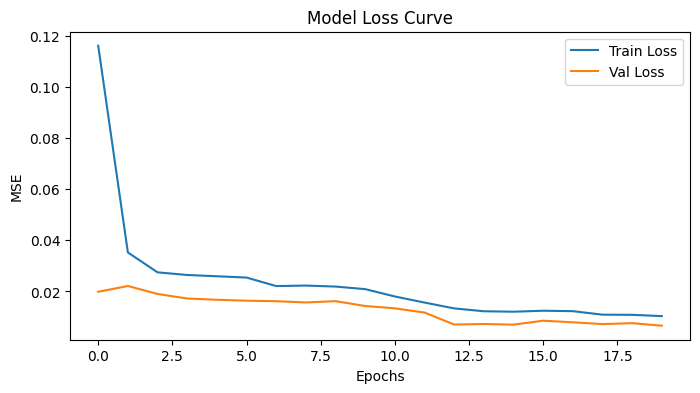

7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 50ms/step


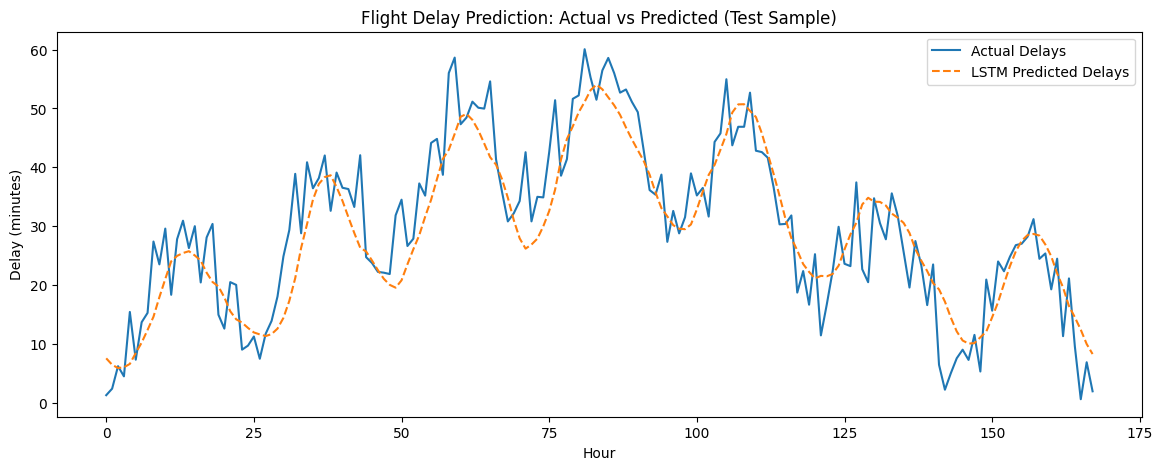

In [5]:
# Plot Loss Curves
plt.figure(figsize=(8, 4))
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Model Loss Curve')
plt.xlabel('Epochs')
plt.ylabel('MSE')
plt.legend()
plt.show()

# Make predictions
predictions_scaled = model.predict(X_test)
predictions = scaler.inverse_transform(predictions_scaled)
y_test_actual = scaler.inverse_transform(y_test)

# Plot Predictions vs Actuals
plt.figure(figsize=(14, 5))
plt.plot(y_test_actual[:168], label='Actual Delays')
plt.plot(predictions[:168], label='LSTM Predicted Delays', linestyle='--')
plt.xlabel('Hour')
plt.ylabel('Delay (minutes)')
plt.title('Flight Delay Prediction: Actual vs Predicted (Test Sample)')
plt.legend()
plt.show()

In [7]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Define a threshold to convert continuous delays into binary outcomes (e.g., threshold = 24.5 minutes)
threshold = np.median(y_test_actual)

# Convert actual and predicted delays to binary labels (1 for High delay, 0 for Low delay)
y_test_binary = (y_test_actual > threshold).astype(int)
predictions_binary = (predictions > threshold).astype(int)

# Calculate classification metrics
accuracy = accuracy_score(y_test_binary, predictions_binary)
precision = precision_score(y_test_binary, predictions_binary)
recall = recall_score(y_test_binary, predictions_binary)
f1 = f1_score(y_test_binary, predictions_binary)

print(f"=== Classification Metrics (Threshold = {threshold:.2f} mins) ===")
print(f"Accuracy : {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"Precision: {precision:.4f} ({precision*100:.2f}%)")
print(f"Recall   : {recall:.4f} ({recall*100:.2f}%)")
print(f"F1 Score : {f1:.4f} ({f1*100:.2f}%)")

=== Classification Metrics (Threshold = 27.41 mins) ===
Accuracy : 0.8520 (85.20%)
Precision: 0.8966 (89.66%)
Recall   : 0.7959 (79.59%)
F1 Score : 0.8432 (84.32%)


### 6. Gated Recurrent Unit (GRU) Model Implementation

Now we will design, train, and evaluate a Gated Recurrent Unit (GRU) model to forecast the flight delays.

In [11]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GRU, Dense, Dropout

# Build the GRU Architecture
gru_model = Sequential([
    GRU(64, return_sequences=True, input_shape=(X_train.shape[1], X_train.shape[2])),
    Dropout(0.2),
    GRU(32, return_sequences=False),
    Dropout(0.2),
    Dense(16, activation='relu'),
    Dense(1)
])

gru_model.compile(optimizer='adam', loss='mean_squared_error')
gru_model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru_2 (GRU)                     │ (None, 24, 64)         │        12,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 24, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_3 (GRU)                     │ (None, 32)             │         9,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,817 (89.13 KB)

 Trainable params: 22,817 (89.13 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
# Train the GRU model
gru_history = gru_model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

Epoch 1/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 4s 44ms/step - loss: 0.0525 - val_loss: 0.0165
Epoch 2/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0227 - val_loss: 0.0113
Epoch 3/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0171 - val_loss: 0.0104
Epoch 4/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0158 - val_loss: 0.0099
Epoch 5/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0139 - val_loss: 0.0097
Epoch 6/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0133 - val_loss: 0.0090
Epoch 7/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - loss: 0.0122 - val_loss: 0.0092
Epoch 8/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - loss: 0.0122 - val_loss: 0.0090
Epoch 9/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - loss: 0.0116 - val_loss: 0.0086
Epoch 10/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0114 - val_loss: 0.0078
Epoch 11/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0108 - val_loss: 0.0077
Epoch 12/20
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - loss: 0.0

7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 55ms/step


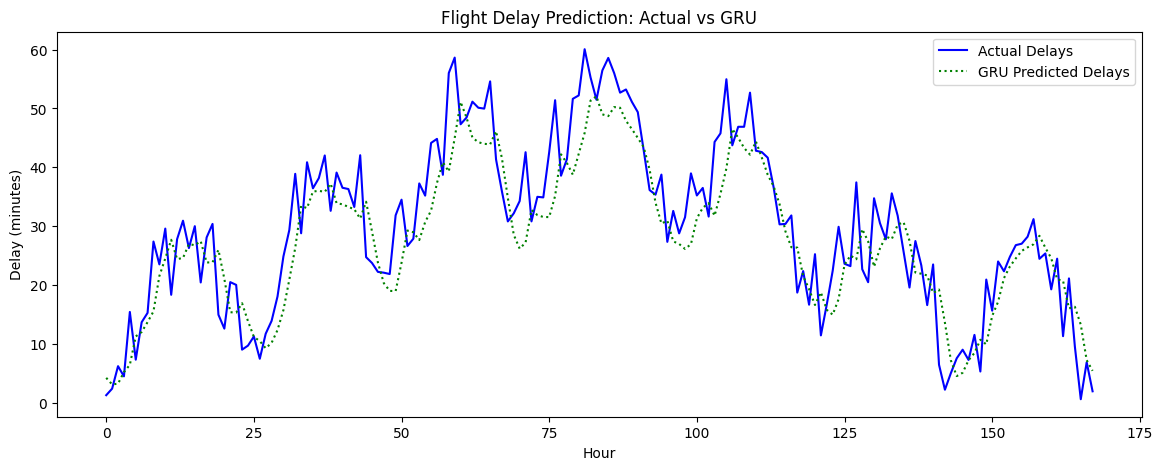

In [13]:
# Make predictions with GRU
gru_predictions_scaled = gru_model.predict(X_test)
gru_predictions = scaler.inverse_transform(gru_predictions_scaled)

# Plot GRU Predictions vs Actuals
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))
plt.plot(y_test_actual[:168], label='Actual Delays', color='blue')
plt.plot(gru_predictions[:168], label='GRU Predicted Delays', linestyle=':', color='green')
plt.xlabel('Hour')
plt.ylabel('Delay (minutes)')
plt.title('Flight Delay Prediction: Actual vs GRU')
plt.legend()
plt.show()

In [15]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, mean_absolute_error, r2_score
import numpy as np

# Evaluate GRU using continuous regression metrics
gru_mae = mean_absolute_error(y_test_actual, gru_predictions)
gru_r2 = r2_score(y_test_actual, gru_predictions)

print("=== GRU Model Regression Metrics ===")
print(f"Mean Absolute Error (MAE): {gru_mae:.3f} minutes")
print(f"R-squared (R2) Score: {gru_r2:.3f}")

# Evaluate GRU using classification metrics with the median threshold
threshold = np.median(y_test_actual)
y_test_binary = (y_test_actual > threshold).astype(int)
gru_predictions_binary = (gru_predictions > threshold).astype(int)

gru_accuracy = accuracy_score(y_test_binary, gru_predictions_binary)
gru_precision = precision_score(y_test_binary, gru_predictions_binary)
gru_recall = recall_score(y_test_binary, gru_predictions_binary)
gru_f1 = f1_score(y_test_binary, gru_predictions_binary)

print("\n=== GRU Classification Metrics ===")
print(f"Accuracy : {gru_accuracy:.4f} ({gru_accuracy*100:.2f}%)")
print(f"Precision: {gru_precision:.4f} ({gru_precision*100:.2f}%)")
print(f"Recall   : {gru_recall:.4f} ({gru_recall*100:.2f}%)")
print(f"F1 Score : {gru_f1:.4f} ({gru_f1*100:.2f}%)")

=== GRU Model Regression Metrics ===
Mean Absolute Error (MAE): 5.335 minutes
R-squared (R2) Score: 0.789

=== GRU Classification Metrics ===
Accuracy : 0.8112 (81.12%)
Precision: 0.8675 (86.75%)
Recall   : 0.7347 (73.47%)
F1 Score : 0.7956 (79.56%)
